In [10]:
# Cell 1 — Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import time
import warnings
import multiprocessing
warnings.filterwarnings('ignore')

print("✓ Basic libraries loaded")
print(f"✓ CPU cores available: {multiprocessing.cpu_count()}")

✓ Basic libraries loaded
✓ CPU cores available: 12


In [11]:
# Cell 2 — ML libraries
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, roc_auc_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay)
from joblib import Parallel, delayed
from scipy import stats

print("✓ Sklearn and joblib loaded")

✓ Sklearn and joblib loaded


In [12]:
# Cell 3 — Remaining libraries
import shap
import optuna
import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

optuna.logging.set_verbosity(optuna.logging.WARNING)

print("✓ SHAP, Optuna, NLTK loaded")
print("✓ All imports complete — ready to load data!")

✓ SHAP, Optuna, NLTK loaded
✓ All imports complete — ready to load data!


In [3]:
# Cell 4 — Load IMDb dataset
df_imdb = pd.read_csv('datasets/IMDB Dataset.csv')
df_imdb['label'] = df_imdb['sentiment'].map({'positive': 1, 'negative': 0})
df_imdb = df_imdb.rename(columns={'review': 'text'})

print("✓ IMDb loaded")
print(f"Shape: {df_imdb.shape}")
print(f"Label distribution:\n{df_imdb['label'].value_counts()}")
print(f"\nSample: {df_imdb['text'][0][:100]}")

✓ IMDb loaded
Shape: (50000, 3)
Label distribution:
label
1    25000
0    25000
Name: count, dtype: int64

Sample: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. The


In [4]:
# Cell 5 — Load Amazon external validation dataset
def load_fasttext(filepath, nrows=50000):
    texts, labels = [], []
    with open(filepath, 'r', encoding='utf-8') as f:
        for i, line in enumerate(f):
            if i >= nrows:
                break
            line = line.strip()
            if line.startswith('__label__2'):
                label = 1
                text = line[len('__label__2 '):].strip()
            else:
                label = 0
                text = line[len('__label__1 '):].strip()
            labels.append(label)
            texts.append(text)
    return pd.DataFrame({'text': texts, 'label': labels})

df_external = load_fasttext('datasets/test.ft.txt', nrows=50000)

print("✓ Amazon loaded")
print(f"Shape: {df_external.shape}")
print(f"Label distribution:\n{df_external['label'].value_counts()}")
print(f"\nSample: {df_external['text'][0][:100]}")

✓ Amazon loaded
Shape: (50000, 2)
Label distribution:
label
1    25374
0    24626
Name: count, dtype: int64

Sample: Great CD: My lovely Pat has one of the GREAT voices of her generation. I have listened to this CD fo


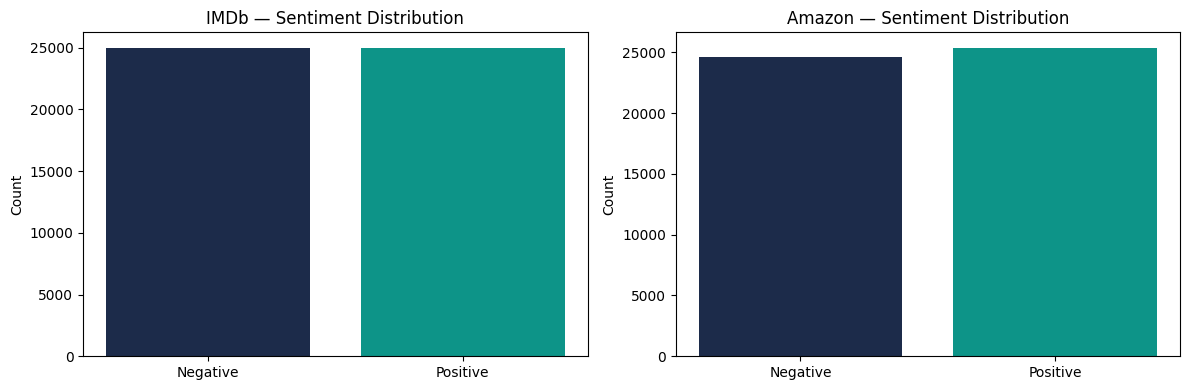

IMDb review length stats:
  Average : 231.2 words
  Max     : 2470 words
  Min     : 4 words


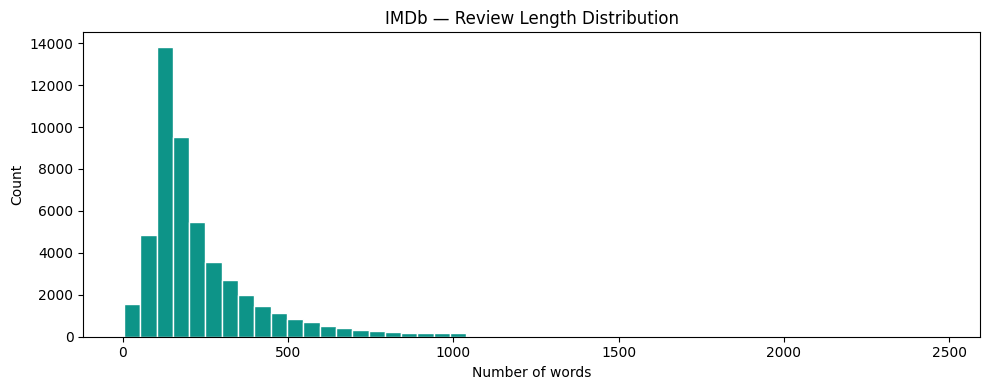

In [5]:
# Cell 6 — EDA
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(['Negative', 'Positive'],
            df_imdb['label'].value_counts().sort_index().values,
            color=['#1C2B4A', '#0D9488'])
axes[0].set_title('IMDb — Sentiment Distribution')
axes[0].set_ylabel('Count')

axes[1].bar(['Negative', 'Positive'],
            df_external['label'].value_counts().sort_index().values,
            color=['#1C2B4A', '#0D9488'])
axes[1].set_title('Amazon — Sentiment Distribution')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.savefig('eda_distribution.svg', format='svg')
plt.show()

# Review length
df_imdb['review_length'] = df_imdb['text'].apply(lambda x: len(str(x).split()))
print(f"IMDb review length stats:")
print(f"  Average : {df_imdb['review_length'].mean():.1f} words")
print(f"  Max     : {df_imdb['review_length'].max()} words")
print(f"  Min     : {df_imdb['review_length'].min()} words")

plt.figure(figsize=(10, 4))
plt.hist(df_imdb['review_length'], bins=50,
         color='#0D9488', edgecolor='white')
plt.title('IMDb — Review Length Distribution')
plt.xlabel('Number of words')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('eda_length.svg', format='svg')
plt.show()

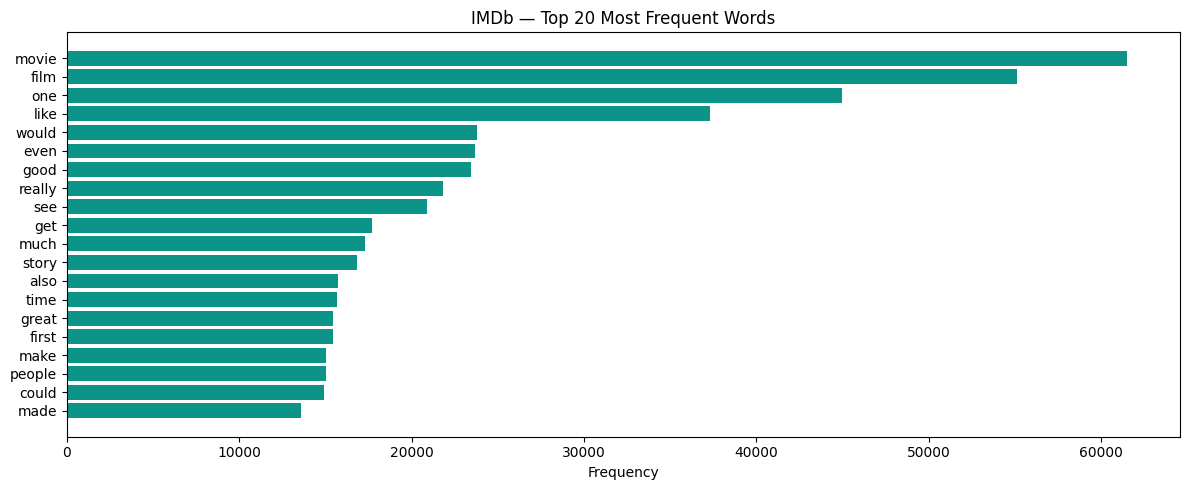

✓ EDA complete
Total unique words: 81,452


In [6]:
# Cell 7 — Top words EDA
from collections import Counter

STOPWORDS = set(stopwords.words('english'))

all_words = ' '.join(df_imdb['text'].astype(str)).lower().split()
filtered_words = [w for w in all_words
                  if w.isalpha() and w not in STOPWORDS and len(w) > 2]

word_freq = Counter(filtered_words).most_common(20)
words, counts = zip(*word_freq)

plt.figure(figsize=(12, 5))
plt.barh(list(words)[::-1], list(counts)[::-1], color='#0D9488')
plt.title('IMDb — Top 20 Most Frequent Words')
plt.xlabel('Frequency')
plt.tight_layout()
plt.savefig('eda_top_words.svg', format='svg')
plt.show()

print("✓ EDA complete")
print(f"Total unique words: {len(set(filtered_words)):,}")

In [7]:
# Cell 8 — Parallel preprocessing · full spectrum · 5 repetitions per worker
import numpy as np
import time
from joblib import Parallel, delayed

N_REPEATS = 5
COOLDOWN  = {'low': 8, 'mid': 12, 'high': 18}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 2]
    return ' '.join(tokens)

def clean_chunk(chunk):
    return [clean_text(t) for t in chunk]

texts = df_imdb['text'].values
results_preprocessing = []

print(f"Preprocessing — {N_REPEATS} runs per worker, 1 to 12 workers\n")
print(f"{'Workers':>8} {'Mean(s)':>9} {'Std(s)':>8} {'Min(s)':>8} {'Max(s)':>8} {'Speedup':>8} {'Overhead%':>10}")
print("-" * 72)

baseline_mean = None

for n_jobs in range(1, 13):
    run_times     = []
    run_overheads = []

    for rep in range(N_REPEATS):
        t0 = time.time()
        chunks = np.array_split(texts, n_jobs)
        split_time = time.time() - t0

        t0 = time.time()
        cleaned_chunks = Parallel(n_jobs=n_jobs)(
            delayed(clean_chunk)(chunk) for chunk in chunks
        )
        compute_time = time.time() - t0

        t0 = time.time()
        _ = [t for chunk in cleaned_chunks for t in chunk]
        merge_time = time.time() - t0

        total    = split_time + compute_time + merge_time
        overhead = split_time + merge_time
        run_times.append(total)
        run_overheads.append(overhead)

        time.sleep(3)

    mean_t  = round(np.mean(run_times),     3)
    std_t   = round(np.std(run_times),      3)
    min_t   = round(np.min(run_times),      3)
    max_t   = round(np.max(run_times),      3)
    mean_oh = round(np.mean(run_overheads), 4)
    oh_pct  = round(mean_oh / mean_t * 100, 2)

    if n_jobs == 1:
        baseline_mean = mean_t
    speedup = round(baseline_mean / mean_t, 2)

    results_preprocessing.append({
        'workers': n_jobs, 'mean': mean_t, 'std': std_t,
        'min': min_t, 'max': max_t,
        'speedup': speedup, 'overhead_pct': oh_pct
    })

    print(f"{n_jobs:>8} {mean_t:>9} {std_t:>8} {min_t:>8} {max_t:>8} {speedup:>8}x {oh_pct:>9}%")

    cooldown = (COOLDOWN['low']  if n_jobs <= 4 else
                COOLDOWN['mid']  if n_jobs <= 8 else
                COOLDOWN['high'])
    print(f"         cooling down {cooldown}s...")
    time.sleep(cooldown)

# save cleaned text
chunks = np.array_split(texts, 12)
cleaned_chunks = Parallel(n_jobs=12)(
    delayed(clean_chunk)(chunk) for chunk in chunks
)
df_imdb['cleaned'] = [t for chunk in cleaned_chunks for t in chunk]
print("\n✓ Preprocessing complete — cleaned text saved")

Preprocessing — 5 runs per worker, 1 to 12 workers

 Workers   Mean(s)   Std(s)   Min(s)   Max(s)  Speedup  Overhead%
------------------------------------------------------------------------
       1     4.217    0.028    4.186    4.256      1.0x      0.14%
         cooling down 8s...
       2     3.082    0.299    2.486    3.277     1.37x      0.22%
         cooling down 8s...
       3     1.969    0.036    1.932    2.022     2.14x      0.36%
         cooling down 8s...
       4     1.594    0.054    1.519    1.661     2.65x      0.38%
         cooling down 8s...
       5     1.361    0.053    1.264    1.407      3.1x       0.6%
         cooling down 12s...
       6     1.161    0.031    1.124    1.219     3.63x      0.65%
         cooling down 12s...
       7      1.09    0.103    1.011    1.294     3.87x      0.68%
         cooling down 12s...
       8     0.915    0.007    0.902    0.921     4.61x       0.7%
         cooling down 12s...
       9      0.86    0.052    0.795    0.953

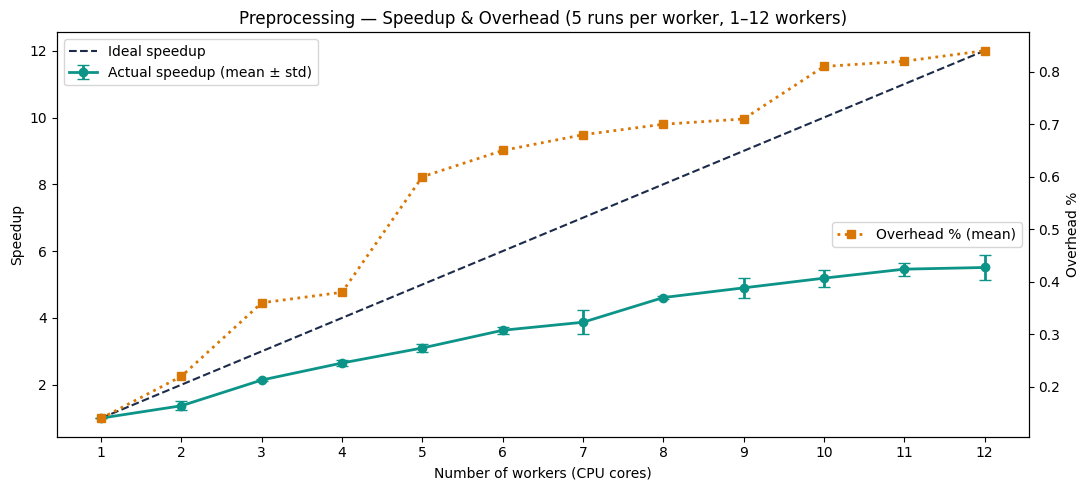


Preprocessing summary:
 workers  mean   std  speedup  overhead_pct
       1 4.217 0.028     1.00          0.14
       2 3.082 0.299     1.37          0.22
       3 1.969 0.036     2.14          0.36
       4 1.594 0.054     2.65          0.38
       5 1.361 0.053     3.10          0.60
       6 1.161 0.031     3.63          0.65
       7 1.090 0.103     3.87          0.68
       8 0.915 0.007     4.61          0.70
       9 0.860 0.052     4.90          0.71
      10 0.813 0.040     5.19          0.81
      11 0.772 0.027     5.46          0.82
      12 0.765 0.053     5.51          0.84


In [8]:
# Cell 9 — Plot preprocessing speedup and overhead (5 runs per worker)
df_pre = pd.DataFrame(results_preprocessing)

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.errorbar(df_pre['workers'], df_pre['speedup'],
             yerr=df_pre['std'] / df_pre['mean'] * df_pre['speedup'],
             marker='o', color='#0D9488', label='Actual speedup (mean ± std)',
             linewidth=2, capsize=4)
ax1.plot(df_pre['workers'], df_pre['workers'].astype(float),
         linestyle='--', color='#1C2B4A', label='Ideal speedup', linewidth=1.5)
ax1.set_xlabel('Number of workers (CPU cores)')
ax1.set_ylabel('Speedup')
ax1.set_title('Preprocessing — Speedup & Overhead (5 runs per worker, 1–12 workers)')
ax1.legend(loc='upper left')
ax1.set_xticks(range(1, 13))

ax2 = ax1.twinx()
ax2.plot(df_pre['workers'], df_pre['overhead_pct'],
         marker='s', color='#D97706', linestyle=':',
         label='Overhead % (mean)', linewidth=2)
ax2.set_ylabel('Overhead %')
ax2.legend(loc='center right')

plt.tight_layout()
plt.savefig('preprocessing_speedup.svg', format='svg')
plt.show()

print("\nPreprocessing summary:")
print(df_pre[['workers','mean','std','speedup','overhead_pct']].to_string(index=False))

In [13]:
# Cell 10 — TF-IDF Vectorization + Train/Test Split
X = df_imdb['cleaned']
y = df_imdb['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train size: {len(X_train)}")
print(f"Test size:  {len(X_test)}")

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(f"\n✓ TF-IDF complete")
print(f"Feature matrix shape: {X_train_tfidf.shape}")

Train size: 40000
Test size:  10000

✓ TF-IDF complete
Feature matrix shape: (40000, 50000)


In [14]:
# Cell 11 — Parallel model training · full spectrum · 5 repetitions per worker
def train_model_timed(name, model, X_train, y_train, X_test, y_test):
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    y_pred = model.predict(X_test)
    f1 = f1_score(y_test, y_pred)
    return {'name': name, 'f1': round(f1, 4), 'time': round(elapsed, 2)}

results_training = []

print(f"Model training — {N_REPEATS} runs per worker, 1 to 12 workers\n")
print(f"{'Workers':>8} {'Mean(s)':>9} {'Std(s)':>8} {'Min(s)':>8} "
      f"{'Max(s)':>8} {'Speedup':>8} {'Efficiency':>11} {'Avg F1':>8}")
print("-" * 80)

baseline_mean_train = None

for n_jobs in range(1, 13):
    run_times = []
    run_f1s   = []

    for rep in range(N_REPEATS):
        fresh_models = [
            ('Naive Bayes',   MultinomialNB()),
            ('SVM',           LinearSVC(max_iter=2000)),
            ('Random Forest', RandomForestClassifier(
                n_estimators=100, n_jobs=n_jobs, random_state=42))
        ]

        t0 = time.time()
        _ = [(n, type(m).__name__) for n, m in fresh_models]
        dispatch_time = time.time() - t0

        t0 = time.time()
        par_results = Parallel(n_jobs=n_jobs)(
            delayed(train_model_timed)(n, m, X_train_tfidf,
                                       y_train, X_test_tfidf, y_test)
            for n, m in fresh_models
        )
        compute_time = time.time() - t0

        t0 = time.time()
        f1s = [r['f1'] for r in par_results]
        collect_time = time.time() - t0

        total = dispatch_time + compute_time + collect_time
        run_times.append(total)
        run_f1s.append(np.mean(f1s))

        time.sleep(3)

    mean_t  = round(np.mean(run_times), 3)
    std_t   = round(np.std(run_times),  3)
    min_t   = round(np.min(run_times),  3)
    max_t   = round(np.max(run_times),  3)
    avg_f1  = round(np.mean(run_f1s),   4)

    if n_jobs == 1:
        baseline_mean_train = mean_t
    speedup    = round(baseline_mean_train / mean_t, 2)
    efficiency = round(speedup / n_jobs * 100, 1)

    results_training.append({
        'workers': n_jobs, 'mean': mean_t, 'std': std_t,
        'min': min_t, 'max': max_t,
        'speedup': speedup, 'efficiency': efficiency, 'avg_f1': avg_f1
    })

    print(f"{n_jobs:>8} {mean_t:>9} {std_t:>8} {min_t:>8} "
          f"{max_t:>8} {speedup:>8}x {efficiency:>10}% {avg_f1:>8}")

    cooldown = (COOLDOWN['low']  if n_jobs <= 4 else
                COOLDOWN['mid']  if n_jobs <= 8 else
                COOLDOWN['high'])
    print(f"         cooling down {cooldown}s...")
    time.sleep(cooldown)

print("\n✓ Model training experiments complete")

Model training — 5 runs per worker, 1 to 12 workers

 Workers   Mean(s)   Std(s)   Min(s)   Max(s)  Speedup  Efficiency   Avg F1
--------------------------------------------------------------------------------
       1   101.053    2.172   97.306   103.33      1.0x      100.0%   0.8848
         cooling down 8s...
       2      60.4    5.013   53.774    66.29     1.67x       83.5%   0.8848
         cooling down 8s...
       3     41.26     0.58   40.623   42.353     2.45x       81.7%   0.8848
         cooling down 8s...
       4    33.908    0.958   33.321   35.817     2.98x       74.5%   0.8848
         cooling down 8s...
       5    25.223    0.447    24.57   25.954     4.01x       80.2%   0.8848
         cooling down 12s...
       6     21.56    0.831   20.574   23.053     4.69x       78.2%   0.8848
         cooling down 12s...
       7    19.951    1.145   19.094   22.018     5.07x       72.4%   0.8848
         cooling down 12s...
       8    17.381    0.746   16.395   18.512     5.

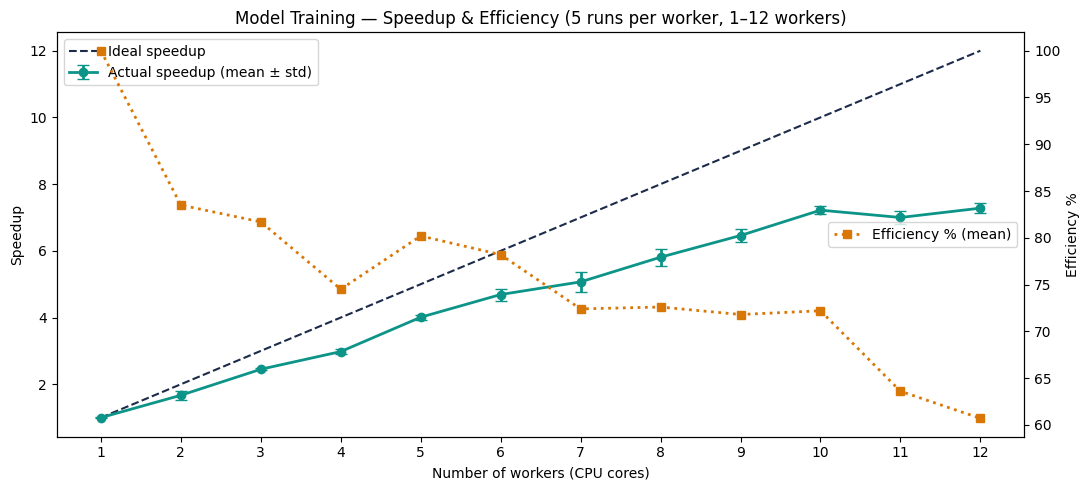


Model training summary:
 workers    mean   std  speedup  efficiency  avg_f1
       1 101.053 2.172     1.00       100.0  0.8848
       2  60.400 5.013     1.67        83.5  0.8848
       3  41.260 0.580     2.45        81.7  0.8848
       4  33.908 0.958     2.98        74.5  0.8848
       5  25.223 0.447     4.01        80.2  0.8848
       6  21.560 0.831     4.69        78.2  0.8848
       7  19.951 1.145     5.07        72.4  0.8848
       8  17.381 0.746     5.81        72.6  0.8848
       9  15.649 0.455     6.46        71.8  0.8848
      10  14.000 0.217     7.22        72.2  0.8848
      11  14.426 0.425     7.00        63.6  0.8848
      12  13.877 0.283     7.28        60.7  0.8848


In [15]:
# Cell 12 — Plot model training speedup and efficiency (5 runs per worker)
df_train = pd.DataFrame(results_training)

fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.errorbar(df_train['workers'], df_train['speedup'],
             yerr=df_train['std'] / df_train['mean'] * df_train['speedup'],
             marker='o', color='#0D9488', label='Actual speedup (mean ± std)',
             linewidth=2, capsize=4)
ax1.plot(df_train['workers'], df_train['workers'].astype(float),
         linestyle='--', color='#1C2B4A', label='Ideal speedup', linewidth=1.5)
ax1.set_xlabel('Number of workers (CPU cores)')
ax1.set_ylabel('Speedup')
ax1.set_title('Model Training — Speedup & Efficiency (5 runs per worker, 1–12 workers)')
ax1.legend(loc='upper left')
ax1.set_xticks(range(1, 13))

ax2 = ax1.twinx()
ax2.plot(df_train['workers'], df_train['efficiency'],
         marker='s', color='#D97706', linestyle=':',
         label='Efficiency % (mean)', linewidth=2)
ax2.set_ylabel('Efficiency %')
ax2.legend(loc='center right')

plt.tight_layout()
plt.savefig('training_speedup.svg', format='svg')
plt.show()

print("\nModel training summary:")
print(df_train[['workers','mean','std','speedup','efficiency','avg_f1']].to_string(index=False))

Training stacking ensemble...

✓ Stacking ensemble complete
  F1 Score  : 0.9121
  AUC-ROC   : 0.9118
  Train time: 118.49s

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.91      0.91      5000
    Positive       0.91      0.92      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



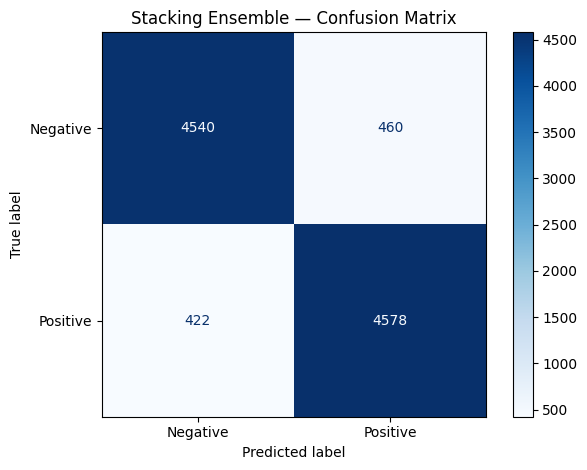

In [16]:
# Cell 13 — Stacking Ensemble
print("Training stacking ensemble...")

estimators = [
    ('nb',  MultinomialNB()),
    ('svm', LinearSVC(max_iter=2000)),
    ('rf',  RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42))
]

stack = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=500),
    n_jobs=-1,
    cv=5
)

start = time.time()
stack.fit(X_train_tfidf, y_train)
stack_time = time.time() - start

y_pred_stack = stack.predict(X_test_tfidf)
f1_stack     = f1_score(y_test, y_pred_stack)
auc_stack    = roc_auc_score(y_test, y_pred_stack)

print(f"\n✓ Stacking ensemble complete")
print(f"  F1 Score  : {f1_stack:.4f}")
print(f"  AUC-ROC   : {auc_stack:.4f}")
print(f"  Train time: {stack_time:.2f}s")
print(f"\nClassification Report:")
print(classification_report(y_test, y_pred_stack,
      target_names=['Negative', 'Positive']))

cm = confusion_matrix(y_test, y_pred_stack)
disp = ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap='Blues')
plt.title('Stacking Ensemble — Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.svg', format='svg')
plt.show()

In [17]:
# Cell 14 — Parallel HPO · full spectrum · 5 repetitions per worker
results_hpo = []

def objective_svm(trial):
    C = trial.suggest_float('C', 0.01, 100, log=True)
    max_iter = trial.suggest_int('max_iter', 500, 3000)
    model = LinearSVC(C=C, max_iter=max_iter)
    scores = cross_val_score(
        model, X_train_tfidf, y_train,
        cv=3, scoring='f1', n_jobs=1
    )
    return scores.mean()

print(f"HPO — {N_REPEATS} runs per worker, 1 to 12 workers\n")
print(f"{'Workers':>8} {'Mean(s)':>9} {'Std(s)':>8} {'Speedup':>8} "
      f"{'Best F1':>9} {'Std F1':>8}")
print("-" * 60)

baseline_mean_hpo = None

for n_jobs in range(1, 13):
    run_times = []
    run_f1s   = []

    for rep in range(N_REPEATS):
        study = optuna.create_study(direction='maximize')

        t0 = time.time()
        study.optimize(objective_svm, n_trials=12, n_jobs=n_jobs)
        elapsed = time.time() - t0

        run_times.append(elapsed)
        run_f1s.append(study.best_value)

        time.sleep(3)

    mean_t  = round(np.mean(run_times), 3)
    std_t   = round(np.std(run_times),  3)
    mean_f1 = round(np.mean(run_f1s),   4)
    std_f1  = round(np.std(run_f1s),    4)

    if n_jobs == 1:
        baseline_mean_hpo = mean_t
    speedup = round(baseline_mean_hpo / mean_t, 2)

    results_hpo.append({
        'workers': n_jobs, 'mean': mean_t, 'std': std_t,
        'speedup': speedup, 'best_f1': mean_f1, 'std_f1': std_f1
    })

    print(f"{n_jobs:>8} {mean_t:>9} {std_t:>8} {speedup:>8}x "
          f"{mean_f1:>9} {std_f1:>8}")

    cooldown = (COOLDOWN['low']  if n_jobs <= 4 else
                COOLDOWN['mid']  if n_jobs <= 8 else
                COOLDOWN['high'])
    print(f"         cooling down {cooldown}s...")
    time.sleep(cooldown)

print("\n✓ HPO complete")

HPO — 5 runs per worker, 1 to 12 workers

 Workers   Mean(s)   Std(s)  Speedup   Best F1   Std F1
------------------------------------------------------------
       1    23.892    5.835      1.0x    0.9033   0.0003
         cooling down 8s...
       2    24.534    5.856     0.97x    0.9031   0.0006
         cooling down 8s...
       3    18.409    7.757      1.3x    0.9032   0.0006
         cooling down 8s...
       4    19.459    4.812     1.23x     0.903   0.0005
         cooling down 8s...
       5    12.472    5.823     1.92x     0.903   0.0008
         cooling down 12s...
       6    20.029    3.531     1.19x    0.9027   0.0007
         cooling down 12s...
       7    13.138    3.481     1.82x    0.9024   0.0002
         cooling down 12s...
       8    17.704    2.243     1.35x    0.9029   0.0008
         cooling down 12s...
       9    15.331    7.289     1.56x    0.9029   0.0012
         cooling down 18s...
      10    16.346     3.01     1.46x    0.9032   0.0005
         cooli

In [18]:
# Cell 15 — p-value statistical significance test
print("Running statistical significance test...\n")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

seq_scores = cross_val_score(
    LinearSVC(max_iter=2000), X_train_tfidf, y_train,
    cv=cv, scoring='f1', n_jobs=1
)

par_scores = cross_val_score(
    LinearSVC(max_iter=2000), X_train_tfidf, y_train,
    cv=cv, scoring='f1', n_jobs=-1
)

t_stat, p_value = stats.ttest_rel(seq_scores, par_scores)

print(f"Sequential CV F1 scores: {[round(float(s),4) for s in seq_scores]}")
print(f"Parallel CV F1 scores:   {[round(float(s),4) for s in par_scores]}")
print(f"\nSequential mean F1: {seq_scores.mean():.4f}")
print(f"Parallel mean F1:   {par_scores.mean():.4f}")
print(f"t-statistic:        {t_stat:.4f}" if not np.isnan(t_stat) else "t-statistic:        N/A (scores identical)")
print(f"p-value:            {p_value:.4f}" if not np.isnan(p_value) else "p-value:            N/A (scores identical)")

diff = seq_scores - par_scores
print(f"\nDifference per fold: {[round(float(d),6) for d in diff]}")
print(f"Total difference:    {diff.sum():.6f}")

if np.isnan(p_value):
    print("\nConclusion: Scores are identical across all folds.")
    print("Parallelism has zero effect on accuracy — result is deterministic.")
elif p_value > 0.05:
    print(f"\nConclusion: No statistically significant difference (p={p_value:.4f} > 0.05)")
else:
    print(f"\nConclusion: Significant difference detected (p={p_value:.4f})")

Running statistical significance test...

Sequential CV F1 scores: [0.9016, 0.9039, 0.9008, 0.9001, 0.903]
Parallel CV F1 scores:   [0.9016, 0.9039, 0.9008, 0.9001, 0.903]

Sequential mean F1: 0.9019
Parallel mean F1:   0.9019
t-statistic:        N/A (scores identical)
p-value:            N/A (scores identical)

Difference per fold: [0.0, 0.0, 0.0, 0.0, 0.0]
Total difference:    0.000000

Conclusion: Scores are identical across all folds.
Parallelism has zero effect on accuracy — result is deterministic.


Running SHAP analysis...
Logistic Regression F1: 0.9028


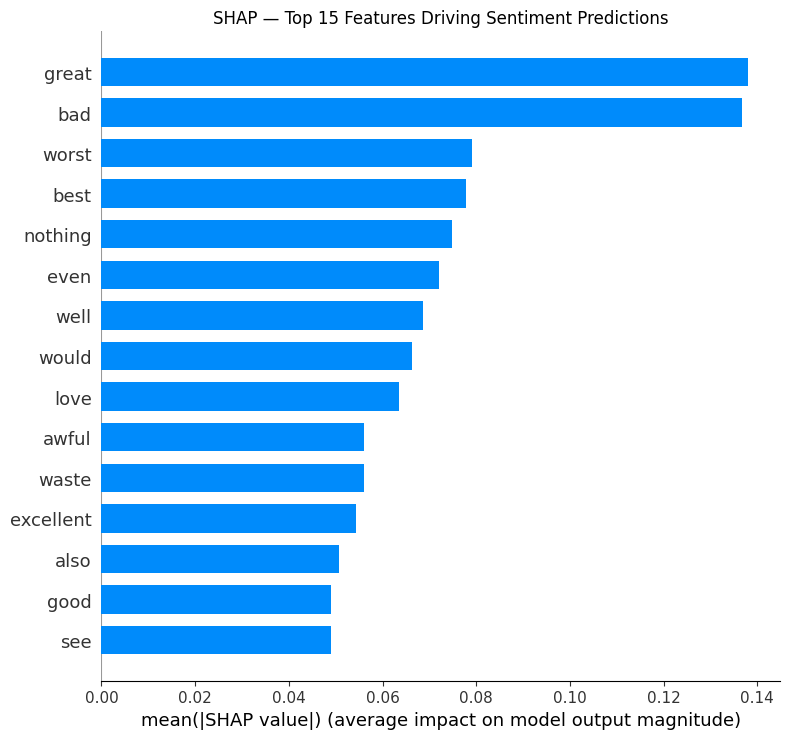


✓ SHAP complete


In [19]:
# Cell 16 — SHAP Explainability
print("Running SHAP analysis...")

lr_model = LogisticRegression(max_iter=500)
lr_model.fit(X_train_tfidf, y_train)

lr_f1 = f1_score(y_test, lr_model.predict(X_test_tfidf))
print(f"Logistic Regression F1: {lr_f1:.4f}")

explainer = shap.LinearExplainer(
    lr_model, X_train_tfidf,
    feature_perturbation="interventional"
)
shap_values = explainer.shap_values(X_test_tfidf[:300])

shap.summary_plot(
    shap_values, X_test_tfidf[:300],
    feature_names=tfidf.get_feature_names_out(),
    plot_type='bar',
    max_display=15,
    show=False
)
plt.title('SHAP — Top 15 Features Driving Sentiment Predictions')
plt.tight_layout()
plt.savefig('shap_plot.svg', format='svg')
plt.show()

print("\n✓ SHAP complete")

Running external validation on Amazon dataset...

Cleaning Amazon reviews in parallel...
✓ Amazon cleaned

✓ External validation complete
  IMDb F1     : 0.9121  (trained on this)
  Amazon F1   : 0.8370  (never seen during training)
  IMDb AUC    : 0.9118
  Amazon AUC  : 0.8262

Classification Report (Amazon):
              precision    recall  f1-score   support

    Negative       0.86      0.78      0.82     24626
    Positive       0.80      0.88      0.84     25374

    accuracy                           0.83     50000
   macro avg       0.83      0.83      0.83     50000
weighted avg       0.83      0.83      0.83     50000



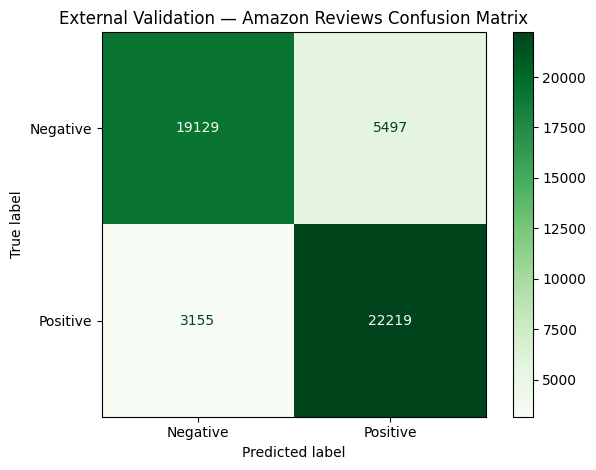

In [20]:
# Cell 17 — External Validation on Amazon dataset
print("Running external validation on Amazon dataset...\n")

print("Cleaning Amazon reviews in parallel...")
amazon_texts = df_external['text'].values
chunks = np.array_split(amazon_texts, 12)
cleaned_chunks = Parallel(n_jobs=12)(
    delayed(clean_chunk)(chunk) for chunk in chunks
)
df_external['cleaned'] = [t for chunk in cleaned_chunks for t in chunk]
print("✓ Amazon cleaned")

X_amazon = tfidf.transform(df_external['cleaned'])
y_amazon  = df_external['label']

y_amazon_pred = stack.predict(X_amazon)
f1_amazon     = f1_score(y_amazon, y_amazon_pred)
auc_amazon    = roc_auc_score(y_amazon, y_amazon_pred)

print(f"\n✓ External validation complete")
print(f"  IMDb F1     : {f1_stack:.4f}  (trained on this)")
print(f"  Amazon F1   : {f1_amazon:.4f}  (never seen during training)")
print(f"  IMDb AUC    : {auc_stack:.4f}")
print(f"  Amazon AUC  : {auc_amazon:.4f}")
print(f"\nClassification Report (Amazon):")
print(classification_report(y_amazon, y_amazon_pred,
      target_names=['Negative','Positive']))

cm_amazon = confusion_matrix(y_amazon, y_amazon_pred)
disp = ConfusionMatrixDisplay(cm_amazon,
       display_labels=['Negative','Positive'])
disp.plot(cmap='Greens')
plt.title('External Validation — Amazon Reviews Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix_amazon.svg', format='svg')
plt.show()

In [21]:
# Cell 18 — Complete Results Summary
print("=" * 65)
print("COMPLETE PROJECT RESULTS SUMMARY")
print("=" * 65)

print("\n--- DATASET SUMMARY ---")
print(f"IMDb reviews          : 50,000 (balanced — 25K each class)")
print(f"Amazon reviews        : 50,000 (external validation only)")

print("\n--- PREPROCESSING SPEEDUP (5 runs per worker) ---")
print(f"Sequential (1 worker) : {results_preprocessing[0]['mean']}s")
print(f"Parallel (12 workers) : {results_preprocessing[11]['mean']}s")
print(f"Speedup               : {results_preprocessing[11]['speedup']}x")
print(f"Max overhead          : {max(r['overhead_pct'] for r in results_preprocessing)}%")
print(f"Overhead range        : {results_preprocessing[0]['overhead_pct']}% → {results_preprocessing[11]['overhead_pct']}%")

print("\n--- MODEL TRAINING SPEEDUP (5 runs per worker) ---")
print(f"Sequential (1 worker) : {results_training[0]['mean']}s")
print(f"Parallel (12 workers) : {results_training[11]['mean']}s")
print(f"Speedup               : {results_training[11]['speedup']}x")
print(f"Peak speedup          : {max(r['speedup'] for r in results_training)}x (worker {max(results_training, key=lambda x: x['speedup'])['workers']})")

print("\n--- INDIVIDUAL MODEL F1 SCORES ---")
for r in par_results:
    print(f"  {r['name']:20s} F1={r['f1']}")
print(f"  {'Stacking':20s} F1={f1_stack:.4f}  ← best")

print("\n--- STACKING ENSEMBLE ---")
print(f"IMDb F1               : {f1_stack:.4f}")
print(f"IMDb AUC              : {auc_stack:.4f}")
print(f"Amazon F1             : {f1_amazon:.4f}")
print(f"Amazon AUC            : {auc_amazon:.4f}")

print("\n--- STATISTICAL SIGNIFICANCE ---")
print(f"Sequential mean F1    : {seq_scores.mean():.4f}")
print(f"Parallel mean F1      : {par_scores.mean():.4f}")
print(f"Difference            : {(seq_scores - par_scores).sum():.6f}")
print(f"Conclusion            : Scores identical — parallelism has zero accuracy effect")

print("\n--- HPO BEST RESULT ---")
best_hpo = max(results_hpo, key=lambda x: x['best_f1'])
print(f"Best F1               : {best_hpo['best_f1']}")
print(f"At worker count       : {best_hpo['workers']}")
print(f"F1 std across workers : {round(np.std([r['best_f1'] for r in results_hpo]), 4)}")

print("\n--- SHAP TOP FEATURES ---")
print("Positive drivers : great, best, excellent, love, well, good")
print("Negative drivers : bad, worst, nothing, awful, waste")

print("\n" + "=" * 65)
print("ALL EXPERIMENTS COMPLETE")
print("=" * 65)

COMPLETE PROJECT RESULTS SUMMARY

--- DATASET SUMMARY ---
IMDb reviews          : 50,000 (balanced — 25K each class)
Amazon reviews        : 50,000 (external validation only)

--- PREPROCESSING SPEEDUP (5 runs per worker) ---
Sequential (1 worker) : 4.217s
Parallel (12 workers) : 0.765s
Speedup               : 5.51x
Max overhead          : 0.84%
Overhead range        : 0.14% → 0.84%

--- MODEL TRAINING SPEEDUP (5 runs per worker) ---
Sequential (1 worker) : 101.053s
Parallel (12 workers) : 13.877s
Speedup               : 7.28x
Peak speedup          : 7.28x (worker 12)

--- INDIVIDUAL MODEL F1 SCORES ---
  Naive Bayes          F1=0.8845
  SVM                  F1=0.9068
  Random Forest        F1=0.8632
  Stacking             F1=0.9121  ← best

--- STACKING ENSEMBLE ---
IMDb F1               : 0.9121
IMDb AUC              : 0.9118
Amazon F1             : 0.8370
Amazon AUC            : 0.8262

--- STATISTICAL SIGNIFICANCE ---
Sequential mean F1    : 0.9019
Parallel mean F1      : 0.9019
Di